<a href="https://colab.research.google.com/github/naubergois/curso-clip-difusao-colab/blob/main/notebooks/01-clip-imagem-e-texto.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 1. Texto e imagem no mesmo espaço

Uma foto e uma frase não cabem na mesma conta. A foto é um retângulo de pixels. A frase é uma fila de palavras. O CLIP faz as duas virarem vetores, listas de números do mesmo tamanho, e mede se apontam para o mesmo lado.

Se a frase descreve a foto, o ângulo entre os vetores fica pequeno e o produto interno sobe. Se a frase fala de outra coisa, o número cai. O modelo aprendeu isso em centenas de milhões de pares tirados da internet: a legenda que estava junto da foto serviu de rótulo. Ninguém entregou uma lista fechada de classes.

Os pesos são o `clip-vit-base-patch32`. É leve e roda na CPU.

> No Colab: **Ambiente de execução → Executar tudo**. GPU é opcional.

In [1]:
import sys
!{sys.executable} -m pip install -q transformers accelerate matplotlib pillow

In [2]:
import os
import warnings

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
warnings.filterwarnings("ignore", message=".*unauthenticated requests.*")

import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from PIL import Image
from transformers import CLIPModel, CLIPProcessor


def baixar(url, destino):
    destino = Path(destino)
    if not destino.exists():
        urllib.request.urlretrieve(url, destino)
    return destino


def dispositivo():
    if torch.cuda.is_available():
        return "cuda"
    if torch.backends.mps.is_available():
        return "mps"
    return "cpu"


def como_vetor(saida):
    """A biblioteca devolve o tensor direto, ou embrulhado. A gente quer o tensor."""
    if torch.is_tensor(saida):
        return saida
    for nome in ("pooler_output", "image_embeds", "text_embeds"):
        valor = getattr(saida, nome, None)
        if torch.is_tensor(valor):
            return valor
    raise TypeError(type(saida))


def normalizar(v):
    return v / v.norm(dim=-1, keepdim=True)


device = dispositivo()
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
model.eval()
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
print("dispositivo:", device)


def pontuar(imagem, textos):
    """Reparte 100% entre os textos recebidos. Não é uma probabilidade do mundo."""
    entradas = processor(text=textos, images=imagem, return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        logits = model(**entradas).logits_per_image[0]
    return logits.softmax(dim=0).detach().cpu()


def vetor_imagem(imagens):
    entradas = processor(images=imagens, return_tensors="pt").to(device)
    with torch.no_grad():
        saida = model.get_image_features(pixel_values=entradas["pixel_values"])
    return normalizar(como_vetor(saida))


def vetor_texto(textos):
    entradas = processor(text=textos, return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        saida = model.get_text_features(
            input_ids=entradas["input_ids"],
            attention_mask=entradas["attention_mask"],
        )
    return normalizar(como_vetor(saida))


def barras(rotulos, valores, titulo):
    plt.figure(figsize=(7, 2.6))
    plt.barh(list(rotulos)[::-1], [float(v) for v in valores][::-1])
    plt.xlim(0, 1)
    plt.title(titulo)
    plt.tight_layout()
    plt.show()

## A foto e três frases

A foto é um ônibus numa rua. As três frases disputam a mesma imagem. Só uma descreve o que está lá.

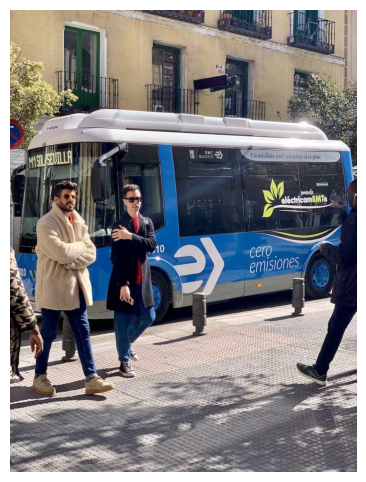

100.0%  a photo of a bus
  0.0%  a photo of a cat
  0.0%  a photo of a dog


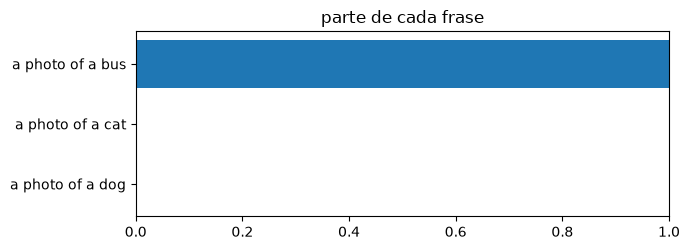

In [3]:
foto = Image.open(baixar("https://www.ultralytics.com/images/bus.jpg", "onibus.jpg")).convert("RGB")
plt.figure(figsize=(5, 6))
plt.imshow(foto)
plt.axis("off")
plt.show()

legendas = [
    "a photo of a bus",
    "a photo of a cat",
    "a photo of a dog",
]
probs = pontuar(foto, legendas)
for texto, p in zip(legendas, probs):
    print(f"{float(p):6.1%}  {texto}")
barras(legendas, probs, "parte de cada frase")
assert abs(float(probs.sum()) - 1) < 1e-4

## O cosseno, antes de virar porcentagem

O softmax reparte 100% entre as frases que você escreveu. Se as três forem ruins, a "vencedora" ainda leva a maior fatia. O número diz quem ganhou a disputa, não que a foto seja aquilo no mundo.

Por baixo, a conta é um cosseno: 1 é a mesma direção, 0 é um ângulo reto. O modelo multiplica esse cosseno por um número aprendido (`logit_scale`) antes do softmax, e a disputa fica bem mais decidida do que o cosseno cru sugere. Um cosseno perto de 0,3 pode virar quase 100%. Gato e cachorro somem na porcentagem. No cosseno, eles ainda estão lá, só que mais longe.

In [4]:
entradas = processor(text=legendas, images=foto, return_tensors="pt", padding=True).to(device)
with torch.no_grad():
    saida = model(**entradas)
img = normalizar(saida.image_embeds)
txt = normalizar(saida.text_embeds)
cosenos = (txt @ img.T).squeeze(1).detach().cpu()
escala = float(model.logit_scale.exp().detach())
print(f"multiplicador do cosseno: {escala:.1f}")
for texto, c in zip(legendas, cosenos):
    print(f"{float(c):6.3f}  {texto}")
assert int(probs.argmax()) == int(cosenos.argmax())

multiplicador do cosseno: 100.0
 0.278  a photo of a bus
 0.180  a photo of a cat
 0.186  a photo of a dog


## Exercícios

Seis perguntas sobre o que acabou de rodar. Escreva a resposta na variável `resposta` e rode a célula. `conferir` diz na hora se fechou. Se travar, abra **Ver solução**.

Rode antes a célula de preparação. Ela só carrega as verificações.

In [ ]:
# @title Preparação dos exercícios (rode, não precisa ler)
_probs = [float(p) for p in probs]
_cos = [float(c) for c in cosenos]
_frases_extra = [
    "a photo of a yellow bus",
    "a photo of a cat",
    "a photo of a dog",
]
_extra = [float(p) for p in pontuar(foto, _frases_extra)]
indice_vencedor = _probs.index(max(_probs))

VERIFICAR = {
    1: lambda r, i=indice_vencedor: int(r) == i,
    2: lambda r, i=indice_vencedor: r == legendas[i],
    3: lambda r, i=indice_vencedor: abs(float(r) - _cos[i]) < 1e-3,
    4: lambda r: int(r) == sum(p > 0.2 for p in _probs),
    5: lambda r: r == _frases_extra[_extra.index(max(_extra))],
    6: lambda r: abs(float(r) - float(model.logit_scale.exp().detach())) < 1e-2,
}

_acertos = {}


def conferir(n, resposta):
    if resposta is None:
        print(f"Exercício {n}: ainda sem resposta.")
        return
    try:
        certo = bool(VERIFICAR[n](resposta))
    except Exception as erro:
        certo = False
        print(f"  (a verificação deu erro: {erro})")
    _acertos[n] = certo
    print(f"Exercício {n}: " + ("✅ certo!" if certo else "❌ ainda não. Releia o enunciado e tente de novo."))


def placar():
    print(f"{sum(_acertos.values())} de {len(VERIFICAR)} exercícios certos.")

### Exercício 1. Quem ganhou

Qual é o índice da frase vencedora em `legendas`? O índice começa em 0.

<details>
<summary>Ver solução</summary>

```python
resposta = int(probs.argmax())
```

</details>

In [ ]:
# Dica: probs guarda uma nota por frase, na mesma ordem.
resposta = None

conferir(1, resposta)

### Exercício 2. A frase, por extenso

Escreva o texto da frase vencedora, não o índice.

<details>
<summary>Ver solução</summary>

```python
resposta = legendas[int(probs.argmax())]
```

</details>

In [ ]:
# Dica: Use o índice para entrar em legendas.
resposta = None

conferir(2, resposta)

### Exercício 3. O cosseno do vencedor

Qual é o cosseno (entre -1 e 1) da frase que ganhou? Esse número está em `cosenos`, antes do softmax.

<details>
<summary>Ver solução</summary>

```python
resposta = float(cosenos[int(probs.argmax())])
```

</details>

In [ ]:
# Dica: O índice do maior valor de probs serve para os dois.
resposta = None

conferir(3, resposta)

### Exercício 4. Acima de 20%

Quantas frases ficaram com probabilidade maior que 0,2?

<details>
<summary>Ver solução</summary>

```python
resposta = int((probs > 0.2).sum())
```

</details>

In [ ]:
# Dica: probs é um tensor. Dá para somar uma comparação.
resposta = None

conferir(4, resposta)

### Exercício 5. Outra disputa

Rode `pontuar` de novo na mesma foto, agora com estas três frases: `a photo of a yellow bus`, `a photo of a cat`, `a photo of a dog`. Responda com o texto da vencedora.

<details>
<summary>Ver solução</summary>

```python
frases = ["a photo of a yellow bus", "a photo of a cat", "a photo of a dog"]
notas = pontuar(foto, frases)
resposta = frases[int(notas.argmax())]
```

</details>

In [ ]:
# Dica: pontuar devolve um tensor na mesma ordem das frases.
resposta = None

conferir(5, resposta)

### Exercício 6. O multiplicador

Qual é o número pelo qual o modelo multiplica o cosseno antes do softmax? É `model.logit_scale.exp()`.

<details>
<summary>Ver solução</summary>

```python
resposta = float(model.logit_scale.exp().detach())
```

</details>

In [ ]:
# Dica: Converta para float.
resposta = None

conferir(6, resposta)

In [ ]:
placar()

## O que fica

CLIP não desenha caixa e não gera imagem. Ele responde qual texto combina com a foto, ou qual foto combina com o texto. A porcentagem só vale dentro das opções que você entregou. Quem desenha a partir da frase é a rede de difusão.